In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv


In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [3]:
# Load dataset
df = pd.read_csv(
    '/kaggle/input/datasets/batooljuaitem/predict-students-dropout-and-academic-success/data.csv',
    sep=';'
)

df.columns = df.columns.str.strip()

# Separate features and target
X = df.drop(columns=['Target'])
y = df['Target']

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Dataset Loaded Successfully!
Dataset Shape: (4424, 37)
Features Shape: (4424, 36)
Target Shape: (4424,)


In [4]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3539, 36)
Testing Data: (885, 36)


In [5]:
# Create models
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'Optimized Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )
}

# Train all models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "Trained Successfully!")

Random Forest Trained Successfully!
Optimized Random Forest Trained Successfully!
Decision Tree Trained Successfully!
Gradient Boosting Trained Successfully!


In [6]:
# Evaluate all models
results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro'),
        'Recall': recall_score(y_test, y_pred, average='macro'),
        'F1-Score': f1_score(y_test, y_pred, average='macro')
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                     Model  Accuracy  Precision  Recall  F1-Score
0            Random Forest    0.7672     0.7214  0.6802    0.6916
1  Optimized Random Forest    0.7763     0.7371  0.6898    0.7026
2            Decision Tree    0.6972     0.6378  0.6397    0.6385
3        Gradient Boosting    0.7593     0.7073  0.6813    0.6902


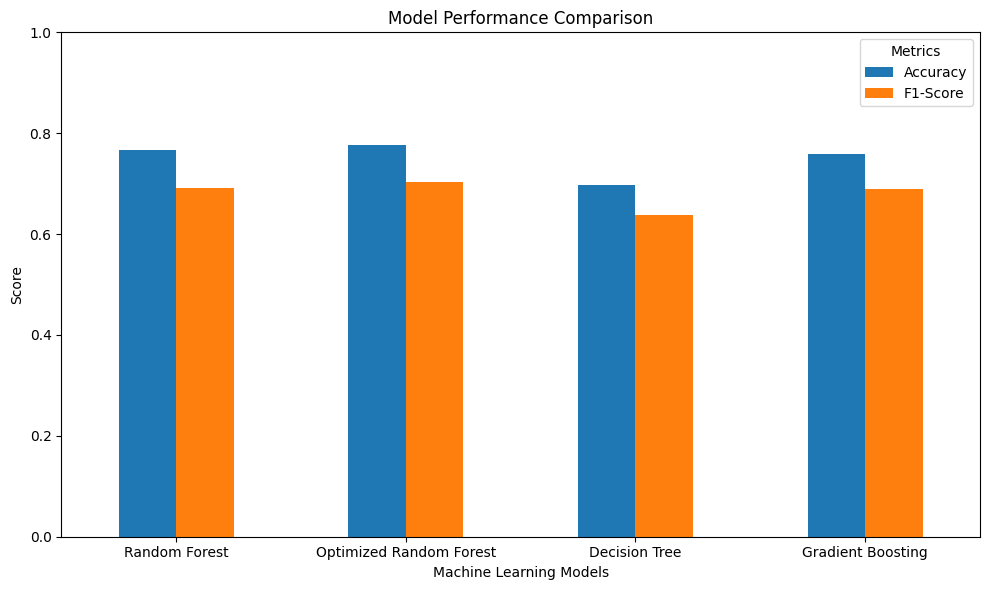

In [7]:
# Plot model performance comparison

results_plot = results_df.set_index('Model')[['Accuracy', 'F1-Score']]

results_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Metrics')
plt.tight_layout()

plt.savefig(
    'model_performance_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

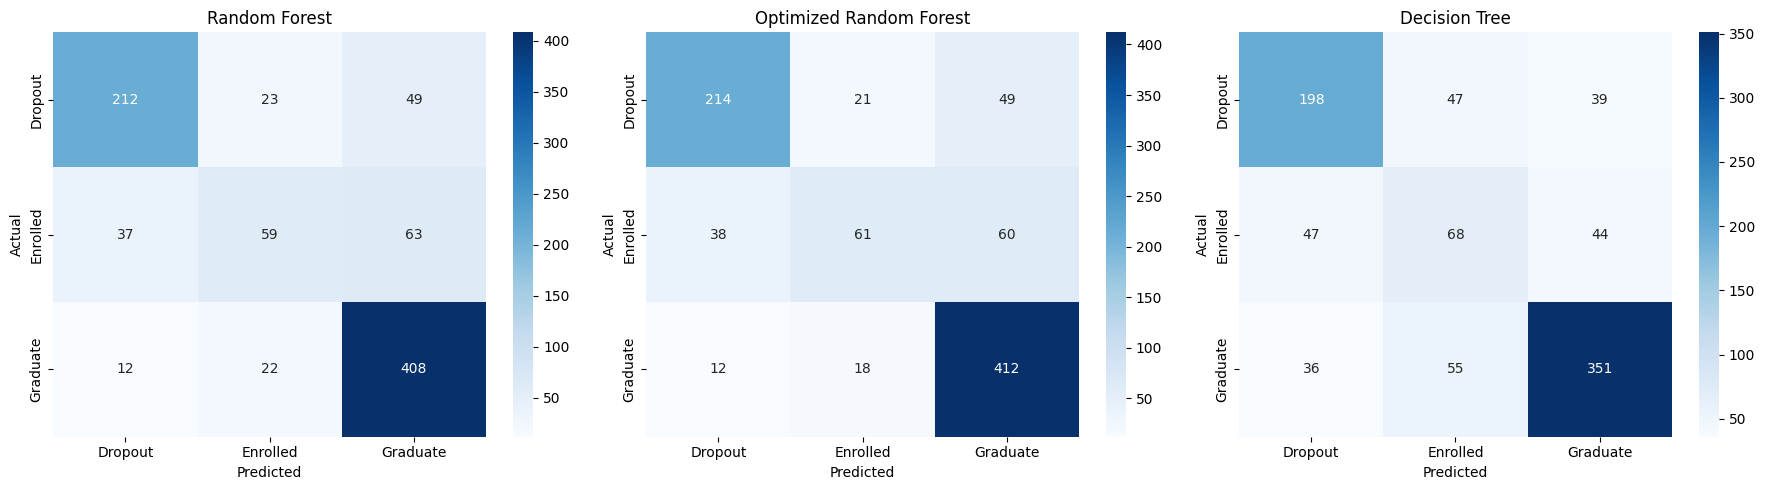

In [8]:
# Plot Confusion Matrices for all models

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()

plt.savefig(
    'confusion_matrices.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [9]:
# Classification Report for Each Model

for name, model in models.items():
    print(f"\n{name}")
    print(classification_report(y_test, model.predict(X_test)))


Random Forest
              precision    recall  f1-score   support

     Dropout       0.81      0.75      0.78       284
    Enrolled       0.57      0.37      0.45       159
    Graduate       0.78      0.92      0.85       442

    accuracy                           0.77       885
   macro avg       0.72      0.68      0.69       885
weighted avg       0.75      0.77      0.75       885


Optimized Random Forest
              precision    recall  f1-score   support

     Dropout       0.81      0.75      0.78       284
    Enrolled       0.61      0.38      0.47       159
    Graduate       0.79      0.93      0.86       442

    accuracy                           0.78       885
   macro avg       0.74      0.69      0.70       885
weighted avg       0.76      0.78      0.76       885


Decision Tree
              precision    recall  f1-score   support

     Dropout       0.70      0.70      0.70       284
    Enrolled       0.40      0.43      0.41       159
    Graduate       0

In [10]:
# Save Model Comparison Results

results_df.to_csv('model_comparison_results.csv', index=False)

print("Results saved successfully!")

Results saved successfully!


In [11]:
# Final Model Evaluation Summary

best_model = results_df.loc[results_df['F1-Score'].idxmax()]

print("FINAL MODEL EVALUATION")
print("----------------------")
print(f"Best Model: {best_model['Model']}")
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall: {best_model['Recall']:.4f}")
print(f"F1-Score: {best_model['F1-Score']:.4f}")

FINAL MODEL EVALUATION
----------------------
Best Model: Optimized Random Forest
Accuracy: 0.7763
Precision: 0.7371
Recall: 0.6898
F1-Score: 0.7026


In [12]:
# Import ROC Curve Requirements

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelEncoder

In [13]:
# Prepare Data for Multi-Class ROC Curve

classes = models['Optimized Random Forest'].classes_

y_test_bin = label_binarize(y_test, classes=classes)

rf_probabilities = models['Optimized Random Forest'].predict_proba(X_test)

print("Classes:", classes)
print("Data prepared successfully!")

Classes: ['Dropout' 'Enrolled' 'Graduate']
Data prepared successfully!


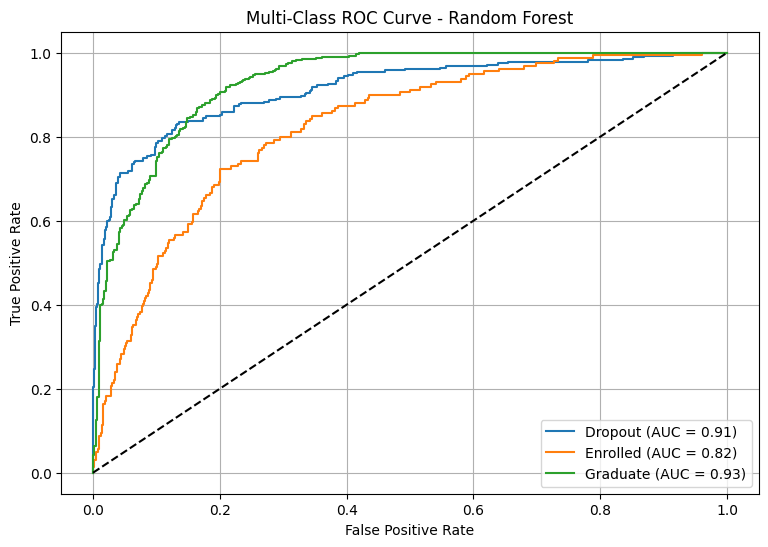

In [14]:
# Plot Multi-Class ROC Curve

plt.figure(figsize=(9, 6))

for i, class_name in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        rf_probabilities[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{class_name} (AUC = {roc_auc:.2f})'
    )

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curve - Random Forest')
plt.legend()
plt.grid()
plt.savefig('roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

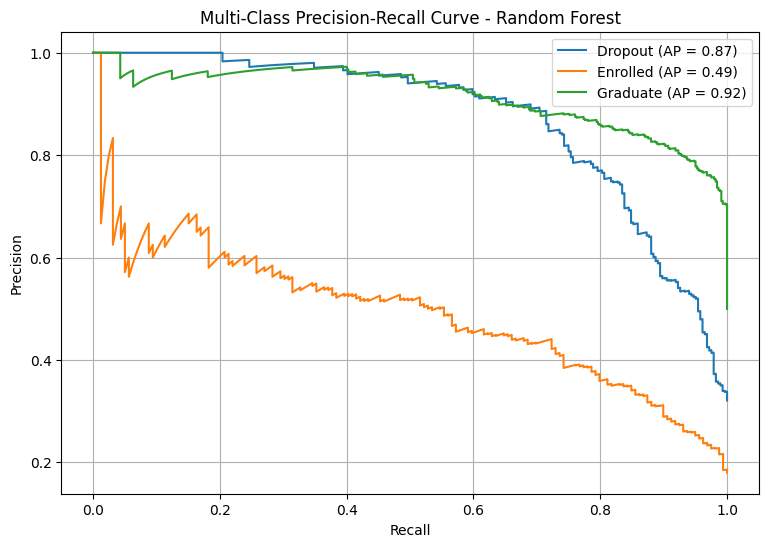

In [15]:
# Plot Multi-Class Precision-Recall Curve

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(9, 6))

for i, class_name in enumerate(classes):
    precision_values, recall_values, thresholds = precision_recall_curve(
        y_test_bin[:, i],
        rf_probabilities[:, i]
    )

    avg_precision = average_precision_score(
        y_test_bin[:, i],
        rf_probabilities[:, i]
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f'{class_name} (AP = {avg_precision:.2f})'
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Multi-Class Precision-Recall Curve - Random Forest')
plt.legend()
plt.grid()
plt.savefig('precision_recall_curve.png', dpi=300, bbox_inches='tight')
plt.show()

In [16]:
# Calculate ROC-AUC and Average Precision for Each Class

from sklearn.metrics import roc_auc_score

class_results = []

for i, class_name in enumerate(classes):
    class_results.append({
        'Class': class_name,
        'ROC-AUC': roc_auc_score(
            y_test_bin[:, i],
            rf_probabilities[:, i]
        ),
        'Average Precision': average_precision_score(
            y_test_bin[:, i],
            rf_probabilities[:, i]
        )
    })

class_results_df = pd.DataFrame(class_results)

print(class_results_df.round(4))

      Class  ROC-AUC  Average Precision
0   Dropout   0.9136             0.8738
1  Enrolled   0.8224             0.4944
2  Graduate   0.9298             0.9153


In [17]:
# Save ROC and Precision-Recall Results

class_results_df.to_csv(
    'roc_precision_recall_results.csv',
    index=False
)

print("ROC and Precision-Recall results saved successfully!")

ROC and Precision-Recall results saved successfully!


In [18]:
# Display All Saved Result Files

import os

print("Current Files:")
for file in os.listdir():
    if file.endswith('.csv') or file.endswith('.png'):
        print(file)

Current Files:
precision_recall_curve.png
model_performance_comparison.png
roc_precision_recall_results.csv
roc_curve.png
model_comparison_results.csv
confusion_matrices.png


In [19]:
# Verify Saved Project Files

import os

for file in sorted(os.listdir()):
    if file.endswith(('.csv', '.png')):
        print("Saved:", file)

Saved: confusion_matrices.png
Saved: model_comparison_results.csv
Saved: model_performance_comparison.png
Saved: precision_recall_curve.png
Saved: roc_curve.png
Saved: roc_precision_recall_results.csv


In [20]:
# Create a Folder for Project Results

import os
import shutil
import glob

results_folder = '/kaggle/working/Project_Results'

os.makedirs(results_folder, exist_ok=True)

for file in glob.glob('/kaggle/working/*.csv') + glob.glob('/kaggle/working/*.png'):
    shutil.copy(file, results_folder)

print("Project results folder created successfully!")
print(os.listdir(results_folder))

Project results folder created successfully!
['precision_recall_curve.png', 'model_performance_comparison.png', 'roc_precision_recall_results.csv', 'roc_curve.png', 'model_comparison_results.csv', 'confusion_matrices.png']
